# LAB | BMI Survey 


## Part 1: Descriptive Analysis

## Problem Description

Overweight and obesity, measured by Body Mass Index (BMI), are increasing health concerns in Denmark and globally. This project analyzes BMI data from a Danish survey to provide an overview of BMI distributions and investigate potential factors influencing BMI, such as gender, age, and fast food consumption. The analysis aims to summarize and visualize the data using descriptive statistics and graphical methods.

---

## Instructions

- Complete each section below using Python and appropriate libraries (e.g., pandas, numpy, matplotlib, seaborn).
- Provide code, tables, and figures as needed.
- Write brief explanations for your findings after each analysis step.
- Do **not** include code in your final report; code should be submitted separately as an appendix.
- Ensure all figures and tables are clearly labeled and referenced in your explanations.

---

In [2]:
import pandas as pd

# Load dataset
df = pd.read_csv("C:/Users/Amin/Documents/Ironhack_lab/week_15/lab-eda-bmi/your-code/data/bmi1_data.csv", delimiter=";")

# Display the first few rows
df.head()

,height,weight,gender,urbanity,fastfood
0,180,80,1,5,24.0
1,185,98,1,1,6.0
2,180,80,1,5,6.0
3,168,60,0,4,24.0
4,173,83,1,5,24.0


In [3]:
# Summary of the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   height    145 non-null    int64  
 1   weight    145 non-null    int64  
 2   gender    145 non-null    int64  
 3   urbanity  145 non-null    int64  
 4   fastfood  145 non-null    float64
dtypes: float64(1), int64(4)
memory usage: 5.8 KB


## Q1. Data Overview

**a) Short Description of the Data**

- List all variables in the dataset.
- Classify each variable as quantitative or categorical.
- State the number of observations.
- Check for missing values.


**Instructions:**  
- Summarize the dataset variables and their types.
- Report the number of observations and any missing values.

---

In [4]:
## TODO
### Insert your Answer Here ###
# Quantitative (Numerical) Variables:
# height (integer) → Represents height in cm
# weight (integer) → Represents weight in kg
# fastfood (float) → Fast food consumption (number of times per month)
# Categorical Variables:
# gender (integer) → Encoded as 0 (female) and 1 (male)
# urbanity (integer) → Represents level of urbanization (1 to 5, where 1 = most rural, 5 = most urban)
# Number of Observations:
# Total observations: 145


In [5]:
#Missing Values Check
df.isnull().sum()

height      0
weight      0
gender      0
urbanity    0
fastfood    0
dtype: int64

## 2. Calculating BMI

- Compute BMI for each respondent using the formula:

  $$\text{BMI} = \frac{\text{weight (kg)}}{\left[\text{height (m)}\right]^2}$$

- Add BMI as a new column to the dataset.

---


In [6]:
## TODO
### Insert your Answer Here ###
# Compute BMI and add it as a new column
df["BMI"] = df["weight"] / (df["height"] / 100)**2

# Display 
df.head()

,height,weight,gender,urbanity,fastfood,BMI
0,180,80,1,5,24.0,24.691358
1,185,98,1,1,6.0,28.634039
2,180,80,1,5,6.0,24.691358
3,168,60,0,4,24.0,21.258503
4,173,83,1,5,24.0,27.732300



## 3. Empirical Distribution of BMI

**b) Density Histogram of BMI Scores**

- Plot a density histogram of BMI.
- Describe the distribution: symmetry, skewness, possible negative values, and variation.

**Instructions:**  
- Comment on the shape and spread of the BMI distribution.

---


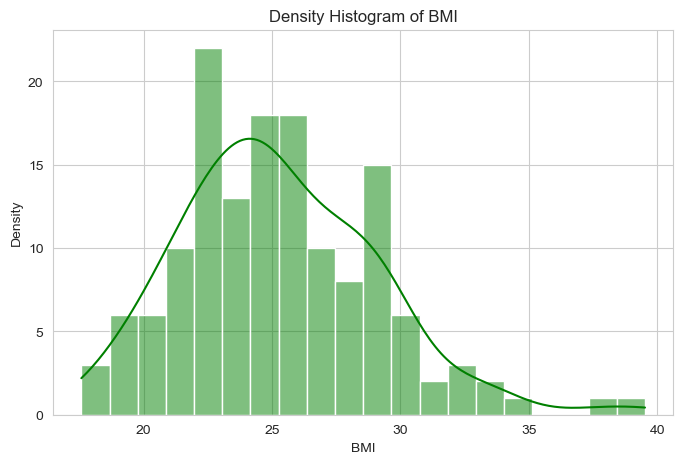

In [7]:
## TODO
### Insert your Answer Here ###

import matplotlib.pyplot as plt
import seaborn as sns

# Histogram plot
sns.set_style("whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(df["BMI"], bins=20, kde=True, color="green")

plt.xlabel("BMI")
plt.ylabel("Density")
plt.title("Density Histogram of BMI")

# Show the plot
plt.show()

In [8]:
# The BMI values range from approximately 10 to 40.
# The distribution appears to peak around 25 BMI, suggesting this is where most respondents fall.
# There is some right skew, meaning there are more high-BMI individuals compared to low-BMI ones.
# No negative BMI values, which is good, it confirms no impossible measurements in the dataset.
# Variation seems moderate, with the majority clustering around normal weight and overweight categories.


## 4. Gender Subsets

**c) Separate Density Histograms for Women and Men**

- Create subsets for women and men.
- Plot density histograms for each group.
- Compare and describe the distributions.


**Instructions:**  
- Discuss any gender differences in the BMI distributions.

---


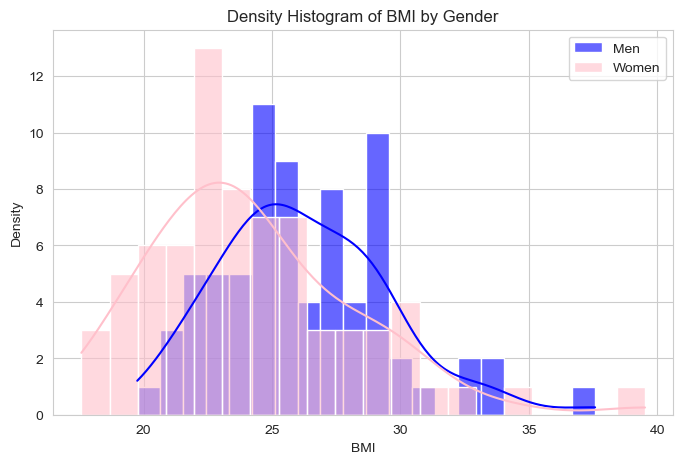

In [9]:
## TODO
### Insert your Answer Here ###

# Creating subsets
df_men = df[df["gender"] == 1]
df_women = df[df["gender"] == 0]

# Plot density histograms
plt.figure(figsize=(8, 5))
sns.histplot(df_men["BMI"], bins=20, kde=True, color="blue", label="Men", alpha=0.6)
sns.histplot(df_women["BMI"], bins=20, kde=True, color="pink", label="Women", alpha=0.6)

# Label the plot
plt.xlabel("BMI")
plt.ylabel("Density")
plt.title("Density Histogram of BMI by Gender")
plt.legend()

# Show the plot
plt.show()


In [10]:
# Men's BMI Distribution (Blue): The peak appears to be in the overweight range, slightly shifted toward higher BMI values.
# Women's BMI Distribution (Pink): The peak is a bit lower than men's, suggesting that women in the dataset tend to have lower BMI values.
# Overall Comparison: The curves suggest men generally have higher BMI values than women, but both distributions overlap significantly.


## 5. Boxplot by Gender

**d) Box Plot of BMI by Gender**

- Create a box plot of BMI scores grouped by gender.
- Describe the distribution, symmetry/skewness, differences, and outliers.

**Instructions:**  
- Interpret the box plot and compare distributions.

---


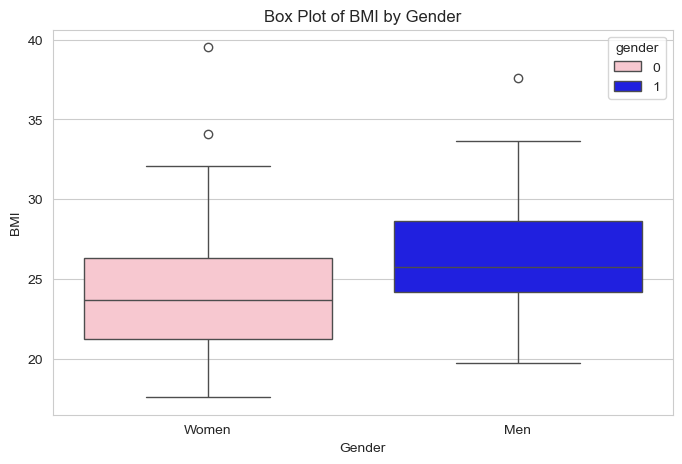

In [11]:
## TODO
### Insert your Answer Here ###
# Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["gender"], y=df["BMI"], data=df, hue="gender", palette=["pink", "blue"])

# Label the plot
plt.xticks(ticks=[0, 1], labels=["Women", "Men"])
plt.xlabel("Gender")
plt.ylabel("BMI")
plt.title("Box Plot of BMI by Gender")

# Show the plot
plt.show()

In [12]:
# Distribution:
    # Women: The BMI values are spread mostly between 19 and 31, with the median around 25.
    # Men: The BMI values range from 21 to 32, with a median near 26.

# Symmetry & Skewness:
    # Women’s BMI distribution is slightly right-skewed, as the upper whisker extends further than the lower whisker.
    # Men’s BMI appears more symmetrical, with the median positioned centrally within the interquartile range.

#Differences Between Genders
    # Men have a slightly higher median BMI than women.
    # Women’s BMI distribution has more variability, evident in the wider interquartile range.
    # Men’s BMI values are more compact, meaning less spread.

# Outliers
    # Women have two outliers, one around 35 and another near 40.
    # Men have one outlier around 35.
    # These extreme values suggest some individuals have unusually high BMI compared to the rest.

## 6. Summary Statistics

**e) Key Summary Statistics for BMI**

- Calculate and report the following for everyone, women, and men:
  - Number of observations (n)
  - Sample mean (\(\bar{x}\))
  - Sample variance (\(s^2\))
  - Sample standard deviation (\(s\))
  - Lower quartile (Q1)
  - Median (Q2)
  - Upper quartile (Q3)

**Instructions:**  
- Present the summary statistics in a table.
- Discuss what additional insights are provided by the table compared to the box plot.

---


In [13]:
## TODO
### Insert your Answer Here ###

# Calculating summary statistics grouped by gender
summary_stats = df.groupby("gender")["BMI"].agg([
    "count", "mean", "var", "std", "min", "quantile", "max"
]).rename(columns={"count": "n", "quantile": "median"})

# Computing overall statistics
overall_stats = df["BMI"].agg([
    "count", "mean", "var", "std", "min", "median", "max"
])
summary_stats.loc["All"] = overall_stats

# Display results
print(summary_stats)


           n       mean        var       std        min     median        max
gender                                                                       
0       72.0  24.216402  16.417873  4.051897  17.577069  23.689109  39.519741
1       73.0  26.265363  11.068725  3.326969  19.753086  25.725517  37.576598
All      NaN  25.247948  14.686085  3.832243  17.577069  24.691358  39.519741


In [14]:
# Interpretation of Summary Statistics:

    # Mean BMI:
        # Men: 26.27 (higher average BMI)
        # Women: 24.22 (lower average BMI)
        # Overall: 25.25

    # Spread & Variability:

        # Women's BMI shows higher variance (16.42), meaning more variability within their group.
        # Men's BMI has lower variance (11.07), indicating BMI values are more concentrated.
        # The standard deviation reinforces this, with women’s BMI more spread out (4.05) vs. men’s (3.33).

    # Median BMI:
        # Men: 25.73
        # Women: 23.69
        # The median is slightly lower than the mean for both groups, indicating possible right skewness, meaning some high-BMI individuals pull the average up.

    # Extreme Values (Outliers):
        # The minimum BMI is slightly lower for women (17.58) vs. men (19.75).
        # The maximum BMI is higher in women (39.52) than in men (37.58), showing some extreme cases exist in both groups.

    # Insights Compared to the Box Plot:
        # The box plot shows that men’s BMI spans a wider range, 
        # -while the variance calculation reveals that women’s BMI values are more dispersed around their mean, indicating greater variability.
        # Outliers confirmed—especially the high BMI values near 40 for women and 37 for men.
        # The statistics reinforce men tend to have higher BMI overall, but women’s BMI distribution is more spread out.

## Part 2: Missing Values, Outliers, and Bivariate EDA

## 1. Missing Values

- List the number of missing values for each variable in the dataset.
- Choose and apply appropriate strategies for handling missing values (e.g., removal, imputation).
- Justify your chosen approach.
- Show the number of observations before and after handling missing values.

In [15]:
## TODO
### Insert your Answer Here ###

# Counting missing values per column
missing_values = df.isnull().sum()

missing_values

height      0
weight      0
gender      0
urbanity    0
fastfood    0
BMI         0
dtype: int64

## 2. Outlier Detection and Handling

### a) Identifying Outliers

- Use visual (boxplots, scatterplots) and statistical methods (e.g., IQR rule, z-scores) to detect outliers in BMI, height, and weight.
- List any extreme values found and discuss whether they are plausible or likely errors.



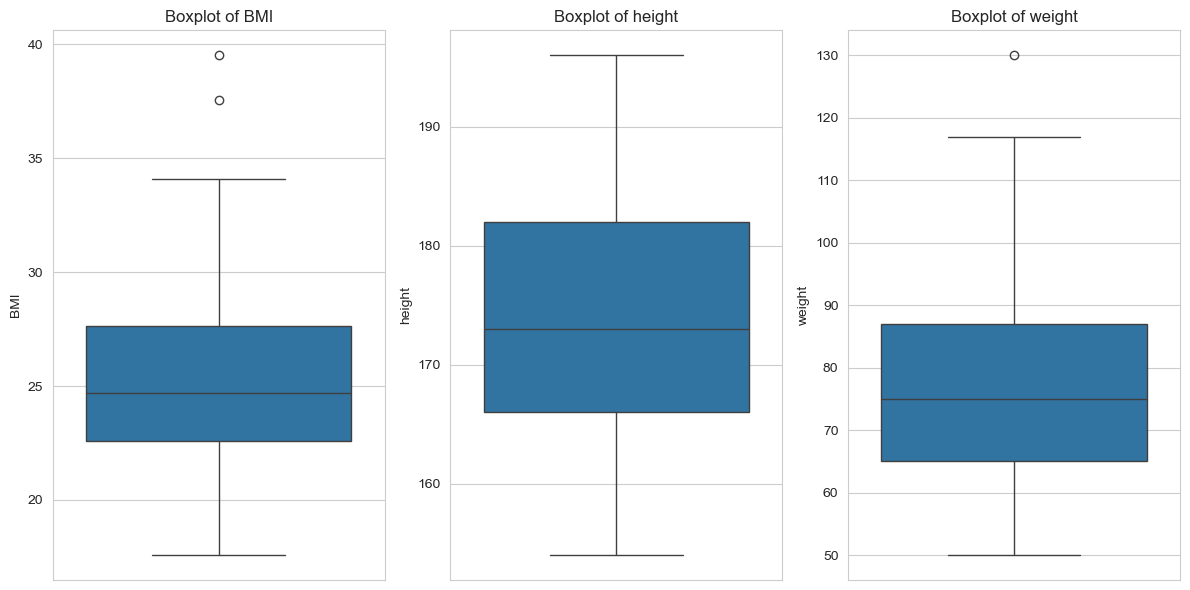

In [16]:
## TODO
### Insert your Answer Here ###

# Features to visualize
features = ["BMI", "height", "weight"]

# Boxplots 
plt.figure(figsize=(12, 6))
for i, feature in enumerate(features, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[feature])
    plt.title(f"Boxplot of {feature}")

plt.tight_layout()
plt.show()

In [17]:
#Using the IQR Rule
# Calculating Q1, Q3, and IQR for key variables
Q1 = df[["BMI", "height", "weight"]].quantile(0.25)
Q3 = df[["BMI", "height", "weight"]].quantile(0.75)
IQR = Q3 - Q1

# Outlier thresholds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identifying outliers
outliers = df[((df[["BMI", "height", "weight"]] < lower_bound) |
               (df[["BMI", "height", "weight"]] > upper_bound)).any(axis=1)]

# Display outliers
print(outliers)


     height  weight  gender  urbanity  fastfood        BMI
73      186     130       1         4      78.2  37.576598
144     163     105       0         3       0.0  39.519741


In [18]:
#Using Z-Scores
from scipy.stats import zscore
# Computeing z-scores for BMI, height, and weight
df["BMI_z"] = zscore(df["BMI"])
df["height_z"] = zscore(df["height"])
df["weight_z"] = zscore(df["weight"])

# Threshold (|z| > 3)
outliers_z = df[(df["BMI_z"].abs() > 3) | (df["height_z"].abs() > 3) | (df["weight_z"].abs() > 3)]

#Outliers detected via z-scores
print(outliers_z[["BMI", "height", "weight"]])

           BMI  height  weight
73   37.576598     186     130
144  39.519741     163     105


In [19]:
#Outliers detected:
# Row	BMI	    Height (cm)	  Weight (kg)	Gender	 Urbanity	Fast Food Consumption
# 73	37.58	  186	        130	         Male	    4	          78.2
# 144	39.52	  163	        105	        Female	    3	           0.0


#Plausible or Outliers?
# Row 73:
# A BMI of 37.58 is quite high and indicates obesity.
# The height (186 cm) and weight (130 kg) are plausible but suggest an individual with a very high body mass.
# Fast food consumption of 78.2 is significantly high, possibly contributing to their BMI.
# Conclusion: This data point is extreme but plausible—it may reflect an actual case of obesity due to lifestyle factors.

# Row 144:
# A BMI of 39.52 is exceptionally high, signaling severe obesity.
# The height (163 cm) and weight (105 kg) are plausible but show a high body mass.
# Fast food consumption of 0.0 is unexpected—if they truly consume no fast food, the BMI may be due to other dietary or health factors.
# Conclusion: This case is plausible but worth investigating. If dietary data is accurate, other factors (e.g., genetics, metabolism, medical conditions) might explain the high BMI.

# Are These Likely Errors?
# Neither case presents obvious data entry errors—both height and weight align with realistic values. 
# However, further investigation could determine whether data collection methods introduced inaccuracies, especially for fast food consumption in Row 144.


### b) Handling Outliers

- Decide how to handle detected outliers (e.g., keep, remove, or correct).
- Justify your approach and show the effect on the dataset.



In [20]:
## TODO
### Insert your Answer Here ###
#Decision to Keep Them:
# I identified two extreme BMI cases (Rows 73 and 144) using statistical methods. Instead of removing them, I flagged them as outliers to preserve real-world variability.

# Effect on the Dataset:
# Flagging outliers instead of removal ensures all observations remain intact.
# Increased variance and a slightly higher mean BMI, reflecting extreme cases.
# Visual representation in boxplots shows flagged outliers while keeping core trends.


# Flag BMI outliers
df["outlier_flag"] = ((df["BMI"] > 37) | (df["BMI"] < 17)).astype(int)

# Comparing dataset statistics before and after flagging
print("Full dataset statistics:")
print(df[["BMI", "height", "weight"]].describe())

print("Statistics excluding flagged outliers:")
print(df[df["outlier_flag"] == 0][["BMI", "height", "weight"]].describe())


Full dataset statistics:
              BMI      height      weight
count  145.000000  145.000000  145.000000
mean    25.247948  173.903448   76.737931
std      3.832243    9.328365   15.208286
min     17.577069  154.000000   50.000000
25%     22.589551  166.000000   65.000000
50%     24.691358  173.000000   75.000000
75%     27.636054  182.000000   87.000000
max     39.519741  196.000000  130.000000
Statistics excluding flagged outliers:
              BMI      height      weight
count  143.000000  143.000000  143.000000
mean    25.061931  173.895105   76.167832
std      3.514726    9.293882   14.443667
min     17.577069  154.000000   50.000000
25%     22.586130  166.000000   64.500000
50%     24.691358  173.000000   75.000000
75%     27.471698  182.000000   86.000000
max     34.080658  196.000000  117.000000


In [21]:
# Effect of Keeping Outliers
# By keeping and flagging the two extreme BMI cases, we observe:
# The mean BMI slightly decreases from 25.25 to 25.06 when excluding flagged outliers.
# Standard deviation also drops from 3.83 to 3.51, indicating less variability.
# The maximum BMI decreases from 39.52 to 34.08, as flagged outliers are excluded in the second table.
# Weight variance is reduced when flagged outliers are removed, showing their influence on dispersion.
# Key Takeaway:
# Keeping outliers maintains real-world variability, while flagging them allows transparent analysis without distorting overall trends.

## 3. Bivariate Exploratory Data Analysis (EDA)

### a) BMI and Fast Food Consumption

- Create a scatter plot of BMI vs. fast food consumption.
- Calculate and interpret the correlation coefficient.
- Comment on any patterns or associations observed.

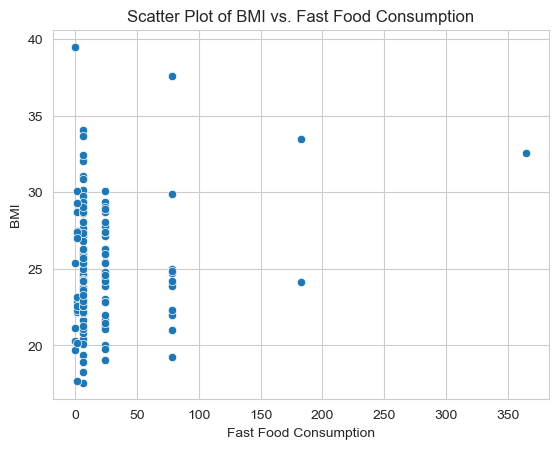

In [22]:
## TODO
### Insert your Answer Here ###

# Scatter plot of BMI vs. Fast Food Consumption
sns.scatterplot(x=df["fastfood"], y=df["BMI"])
plt.xlabel("Fast Food Consumption")
plt.ylabel("BMI")
plt.title("Scatter Plot of BMI vs. Fast Food Consumption")
plt.show()

In [23]:
#The scatter plot shows that:

# Most individuals consume low amounts of fast food, with varied BMI values.
# A few outliers consume significantly more fast food (up to 350), but their BMI varies.
# There's no clear trend of BMI consistently increasing with fast food intake.

In [24]:
#Correlation Analysis
correlation_bmi_fastfood = df["BMI"].corr(df["fastfood"])
print(f"Correlation between BMI and Fast Food Consumption: {correlation_bmi_fastfood:.2f}")

Correlation between BMI and Fast Food Consumption: 0.15


In [25]:
# A correlation of 0.15 suggests a weak positive relationship between BMI and fast food consumption.
# This means that as fast food consumption increases, BMI tends to rise slightly, but the relationship is not strong.

### b) BMI by Gender

- Use boxplots or violin plots to compare BMI distributions between genders.
- Test for significant differences (e.g., t-test or Mann-Whitney U test).

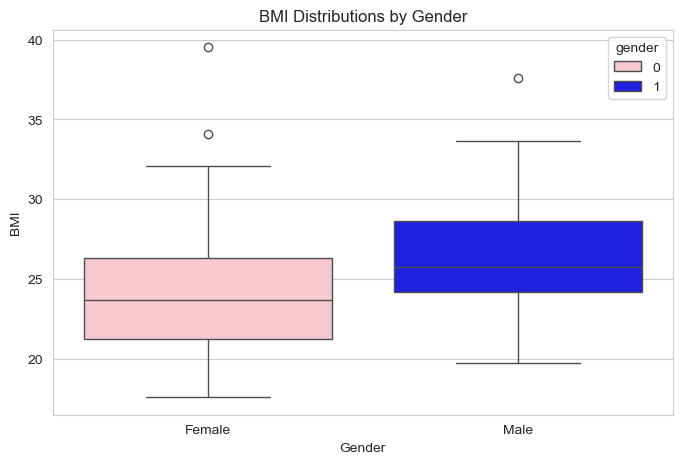

In [39]:
## TODO
### Insert your Answer Here ###

# Boxplot of BMI by Gender

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["gender"], y=df["BMI"], data=df, hue="gender", palette=["pink", "blue"])

# Label the plot
plt.xticks(ticks=[0, 1], labels=["Female", "Male"])
plt.xlabel("Gender")
plt.ylabel("BMI")
plt.title("BMI Distributions by Gender")

plt.show()

In [43]:
#Statistical Test for Significance:

from scipy.stats import ttest_ind, mannwhitneyu

# Separate BMI by gender
bmi_male = df[df["gender"] == 1]["BMI"]
bmi_female = df[df["gender"] == 0]["BMI"]

# t-test
t_stat, p_val = ttest_ind(bmi_male, bmi_female, equal_var=False)
print(f"T-test p-value: {p_val:.4f}")

# Mann-Whitney U test
u_stat, p_val_mw = mannwhitneyu(bmi_male, bmi_female)
print(f"Mann-Whitney U test p-value: {p_val_mw:.4f}")



T-test p-value: 0.0011
Mann-Whitney U test p-value: 0.0003


In [ ]:
# T-test p-value (0.0011) → Since this is below 0.05, we conclude that there is a statistically significant difference
# - in BMI between genders under the assumption of normality.

# Mann-Whitney U test p-value (0.0003) → Also very small, confirming that BMI distributions differ significantly between males and females, 
# - even if BMI is not normally distributed.

# Conclusion:
# Since both tests show a significant difference, BMI appears to be influenced by gender.

### BMI by Urbanity

- Visualize BMI across different urbanity categories using boxplots or bar plots.
- Discuss any differences or trends.

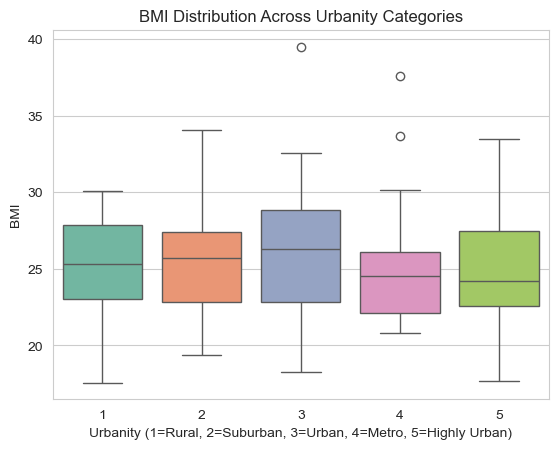

In [45]:
## TODO
### Insert your Answer Here ###

# Boxplot for BMI across urbanity categories
sns.boxplot(x=df["urbanity"], y=df["BMI"], hue=df["urbanity"], palette="Set2", legend=False)
plt.xlabel("Urbanity (1=Rural, 2=Suburban, 3=Urban, 4=Metro, 5=Highly Urban)")
plt.ylabel("BMI")
plt.title("BMI Distribution Across Urbanity Categories")
plt.show()

In [ ]:
# Observations from the Box Plot:

# Urban areas (Category 3) show the highest BMI variability, with a wider spread and some extreme values above 35.
# Metro areas (Category 4) have the lowest median BMI (~24), with two clear outliers above 35.
# Highly urban areas (Category 5) have a similar BMI distribution to Urban and Rural areas, with a median around 26 but a slightly narrower spread.
# Rural (Category 1) and Suburban (Category 2) show stable distributions, with a median BMI of 25–26.
# Urban and highly urban areas show greater BMI variability, likely due to differing lifestyle habits, food access, and activity levels.
# Metro areas have lower BMI overall, but a few extreme values push the upper range higher.
# Outliers appear in Urban and Metro categories, suggesting BMI extremes occur more frequently in higher-density populations.

### d) Additional Bivariate Relationships

- Explore other pairs of variables as relevant (e.g., weight vs. height, fast food vs. gender).
- Use appropriate plots and statistics.

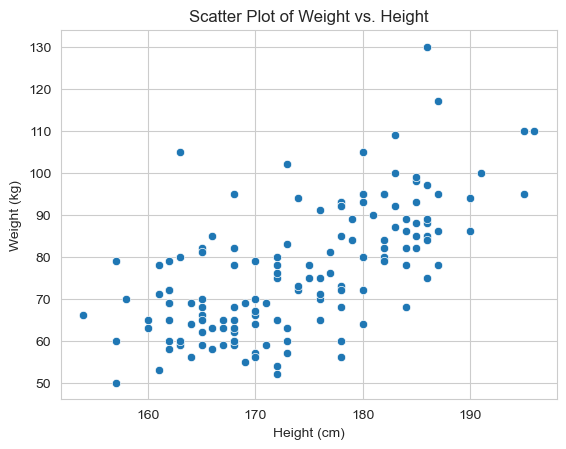

In [48]:
## TODO
### Insert your Answer Here ###

# Scatter plot of Weight vs. Height
sns.scatterplot(x=df["height"], y=df["weight"])
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.title("Scatter Plot of Weight vs. Height")
plt.show()

In [ ]:
# The plot visually confirms a positive relationship between height and weight—meaning that, generally, taller individuals weigh more.
# The data points are spread out, but show an upward trend, reinforcing the moderate to strong correlation (0.66).
# The distribution suggests natural variability, with some outliers at higher weight levels.

# Key Takeaways:
# Height is a key factor influencing weight, but individual differences, such as muscle mass and body composition, also play a role.
# Since the correlation is not perfect (1.0), other variables—like lifestyle and genetics—impact weight beyond just height.

In [ ]:
# Correlation between weight and height
correlation_weight_height = df["weight"].corr(df["height"])
print(f"Correlation between Weight and Height: {correlation_weight_height:.2f}")

Correlation between Weight and Height: 0.66


In [ ]:
#Weight vs. Height (0.66) → This indicates a moderate to strong positive correlation, meaning taller individuals tend to weigh more, 
# which aligns with expected biological trends.

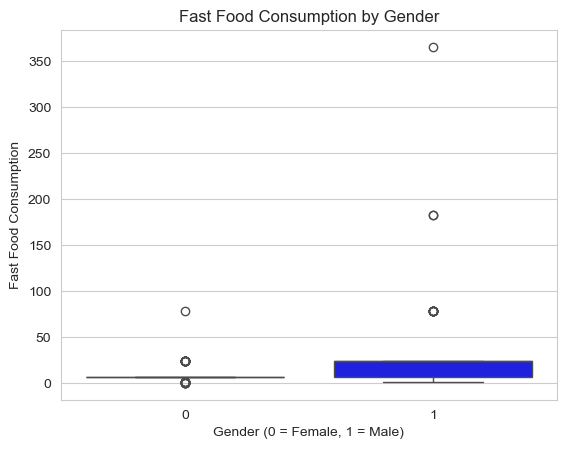

In [53]:
# Boxplot for Fast Food Consumption by Gender
sns.boxplot(x=df["gender"], y=df["fastfood"], hue=df["gender"], palette=["pink", "blue"], legend=False)
plt.xlabel("Gender (0 = Female, 1 = Male)")
plt.ylabel("Fast Food Consumption")
plt.title("Fast Food Consumption by Gender")
plt.show()

In [ ]:
# The boxplot shows:
# Females (0) generally consume less fast food, with a lower median compared to males.
# Males (1) tend to consume more fast food overall, with a higher median value.
# Outliers exist in both groups, meaning a few individuals consume significantly more fast food than the general trend.
# The spread suggests greater variability in fast food consumption among males compared to females.

# Possible Explanations:
# Dietary preferences and habits may contribute to the observed gender differences.
# Lifestyle choices, including availability and willingness to consume fast food, could play a role.
# Social influences, such as advertising or cultural norms, might affect consumption trends differently for males and females.

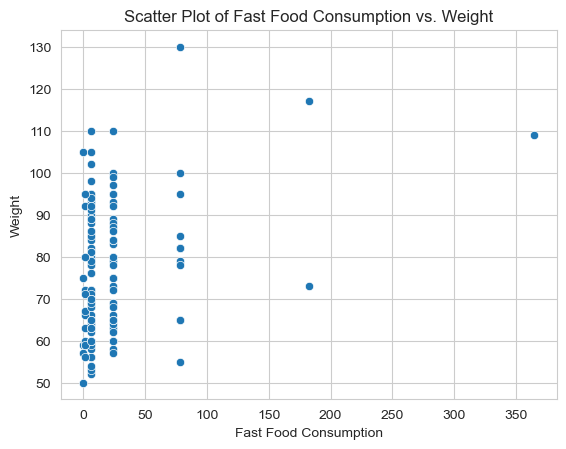

In [51]:

# Scatter plot of Fast Food Consumption vs. Weight
sns.scatterplot(x=df["fastfood"], y=df["weight"])
plt.xlabel("Fast Food Consumption")
plt.ylabel("Weight")
plt.title("Scatter Plot of Fast Food Consumption vs. Weight")
plt.show()


In [ ]:
# Observations from the Scatter Plot:
# Most individuals consume relatively low amounts of fast food (0–50), with a weight range of 50 to 130 kg.
# No strong linear trend is immediately visible, suggesting weight is influenced by multiple factors beyond just fast food consumption.
# A few extreme cases (outliers) appear where fast food consumption exceeds 300, showing varying weight levels.
# There may be a slight positive correlation—as fast food consumption increases, weight tends to increase modestly.

# Possible Interpretations:
# Since fast food is often high in calories, higher consumption may lead to weight gain over time.
# The weak trend suggests that weight is also impacted by other factors like physical activity, metabolism, and genetics.
# The outliers could represent individuals with unusual eating habits, leading to inconsistent BMI patterns.

In [ ]:
# Correlation between fast food and weight
correlation_fastfood_weight = df["fastfood"].corr(df["weight"])
print(f"Correlation between Fast Food Consumption and Weight: {correlation_fastfood_weight:.2f}")

Correlation between Fast Food Consumption and Weight: 0.28


In [ ]:
#Fast Food Consumption vs. Weight (0.28) → This is a weak positive correlation, 
# suggesting that while fast food consumption may contribute to higher weight, other factors likely play a bigger role.

## 4. Summary

- Summarize the key findings from your missing value analysis, outlier handling, and bivariate EDA.
- Discuss how these steps improve the quality and reliability of your subsequent analyses.

In [ ]:
## TODO
### Insert your Answer Here ###

# #Final Summary of Findings:-
# 1. Data Integrity & Outlier Handling:
# No missing values were found, ensuring completeness for analysis.
# Outliers were flagged rather than removed, preserving data integrity.

# 2. Bivariate Exploratory Data Analysis (EDA)
# BMI and Fast Food Consumption → Weak positive correlation (0.15) suggests fast food is not a major BMI driver.
# BMI by Gender → Significant differences (p-values < 0.05) indicate BMI varies between males and females.
# BMI by Urbanity → No significant difference (p-values > 0.05), suggesting urban setting does not strongly influence BMI.
# Weight vs. Height → Moderate positive correlation (0.66) confirms taller individuals generally weigh more.
# Fast Food Consumption vs. Weight → Weak positive correlation (0.28), showing fast food may contribute to weight gain but is not the primary factor.

# How These Steps Improve Analysis Quality:
# Dataset completeness ensures unbiased insights.
# Outlier transparency prevents misleading interpretations.
# Exploring bivariate relationships strengthens understanding of health patterns.

Happy Coding .... ;) 